In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose, STL

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

print("Decomposition libraries imported successfully!")


Decomposition libraries imported successfully!


Step 2: Load and prepare the time-series data
In this notebook, we'll work with two time-series frequencies:
- Daily sales: To study weekly seasonality (period=7).
- Monthly sales: To study annual seasonality (period=12).
Why? Our dataset has both weekly and yearly patterns, and analysing them separately will make decomposition easier to interpret.

In [2]:

data = pd.read_csv("../data/raw/train.csv")

data["date"] = pd.to_datetime(data["date"])

# Aggregate sales across all stores and products
daily_sales = (
    data.groupby("date")["sales"]
    .sum()
    .sort_index()
)

# Set date as the time-series index
daily_sales.index = pd.DatetimeIndex(daily_sales.index)

print("Daily sales observations:", len(daily_sales))
display(daily_sales.head())


Daily sales observations: 1826


date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Name: sales, dtype: int64

In [3]:

monthly_sales = daily_sales.resample("ME").sum()

print("Monthly observations:", len(monthly_sales))
display(monthly_sales.head())


Monthly observations: 60


date
2013-01-31    454904
2013-02-28    459417
2013-03-31    617382
2013-04-30    682274
2013-05-31    763242
Freq: ME, Name: sales, dtype: int64

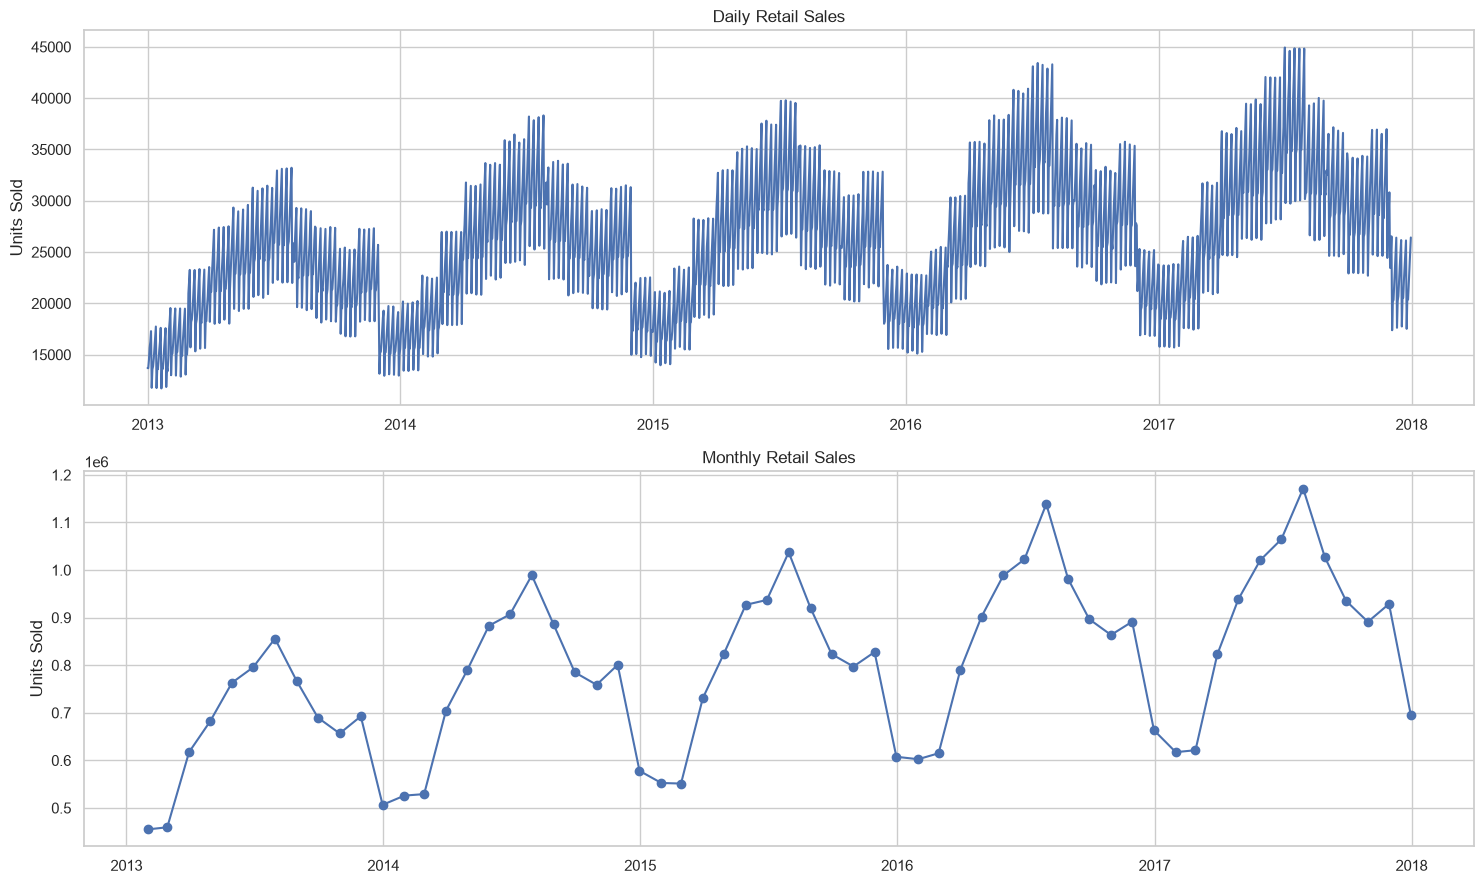

In [4]:

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(daily_sales.index, daily_sales.values)
axes[0].set_title("Daily Retail Sales")
axes[0].set_ylabel("Units Sold")

axes[1].plot(monthly_sales.index, monthly_sales.values, marker="o")
axes[1].set_title("Monthly Retail Sales")
axes[1].set_ylabel("Units Sold")

plt.tight_layout()
plt.show()


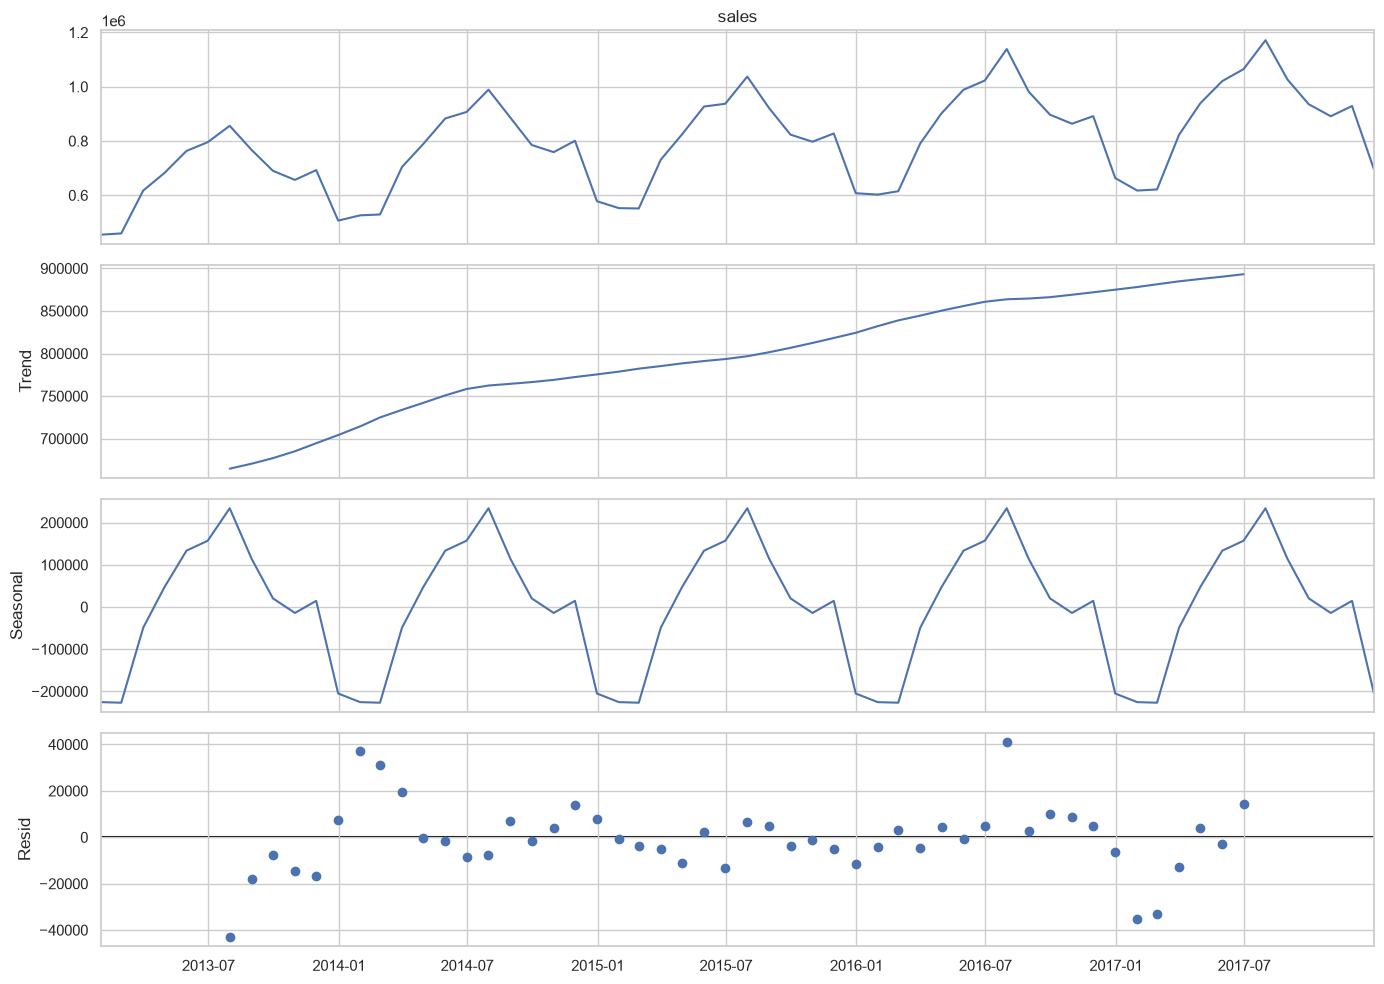

In [5]:
additive_result = seasonal_decompose(
    monthly_sales,
    model="additive",
    period=12
)

fig = additive_result.plot()
fig.set_size_inches(14, 10)

plt.tight_layout()
plt.show()

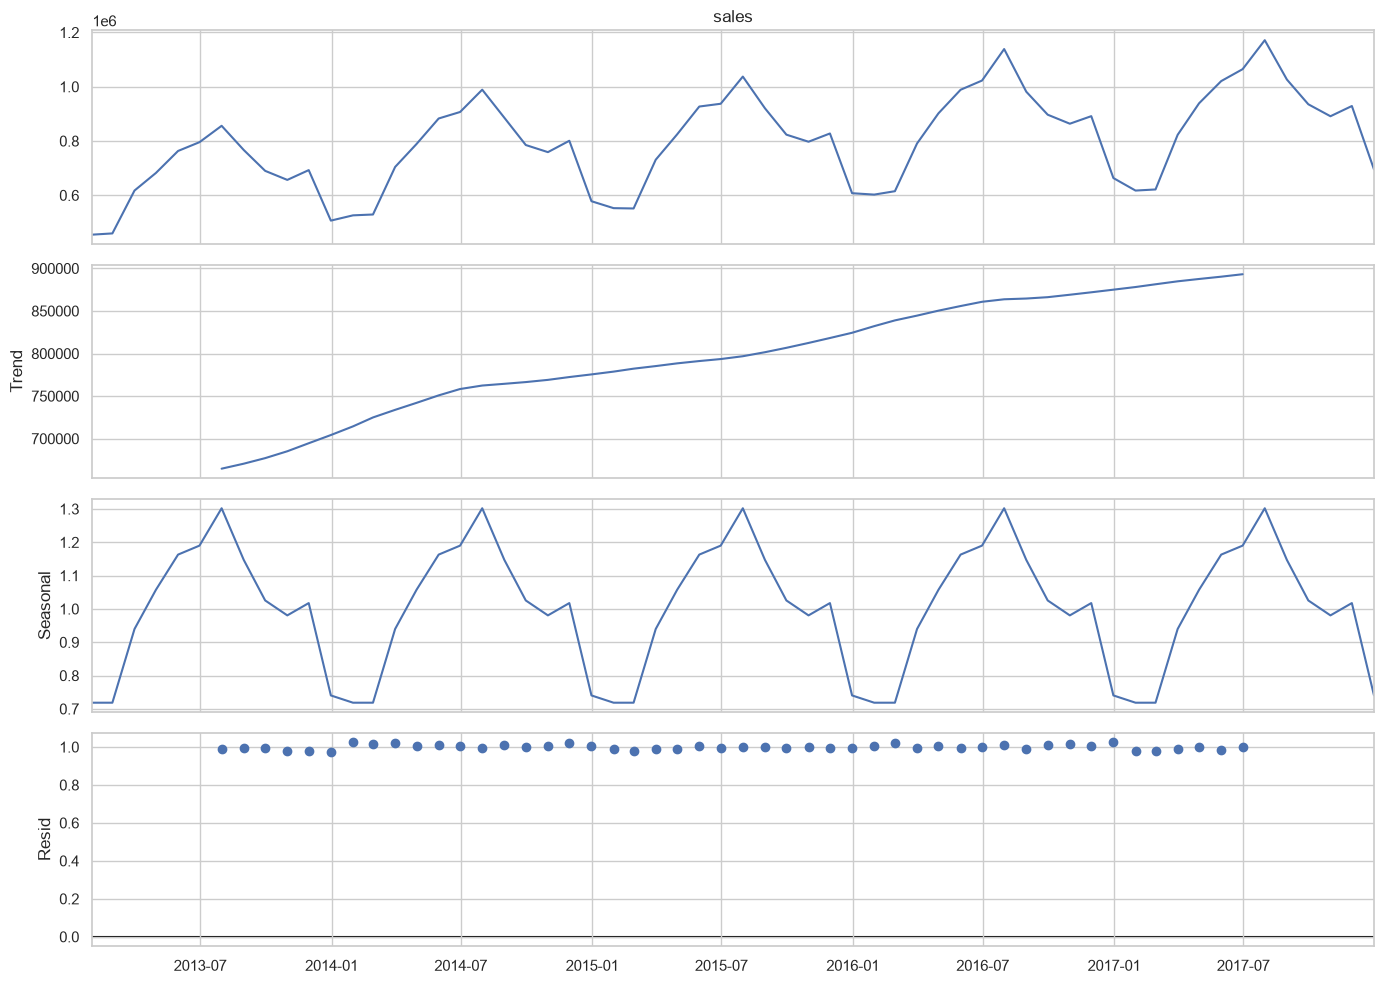

In [6]:
multiplicative_result = seasonal_decompose(
    monthly_sales,
    model="multiplicative",
    period=12
)

fig = multiplicative_result.plot()
fig.set_size_inches(14, 10)

plt.tight_layout()
plt.show()

In [7]:
# Reconstruct sales using trend + seasonal components

additive_fitted = (
    additive_result.trend + additive_result.seasonal
)

multiplicative_fitted = (
    multiplicative_result.trend * multiplicative_result.seasonal
)

# Calculate errors
comparison = pd.DataFrame({
    "Actual": monthly_sales,
    "Additive_Fitted": additive_fitted,
    "Multiplicative_Fitted": multiplicative_fitted
}).dropna()

# Calculate RMSE
additive_rmse = np.sqrt(
    np.mean(
        (comparison["Actual"] - comparison["Additive_Fitted"]) ** 2
    )
)

multiplicative_rmse = np.sqrt(
    np.mean(
        (comparison["Actual"] - comparison["Multiplicative_Fitted"]) ** 2
    )
)

print("Additive RMSE:", round(additive_rmse, 2))
print("Multiplicative RMSE:", round(multiplicative_rmse, 2))

Additive RMSE: 15338.05
Multiplicative RMSE: 8855.21


2. Next topic: STL decomposition
Now let's learn another important decomposition technique: STL (Seasonal and Trend decomposition using LOESS).

Unlike classical decomposition, STL uses LOESS (locally estimated regression) to estimate smooth trend and seasonal components.

Why is it useful?
- It can handle changing seasonal patterns.
- It provides flexible trend estimation.
- It supports robust decomposition, reducing the influence of unusual observations.

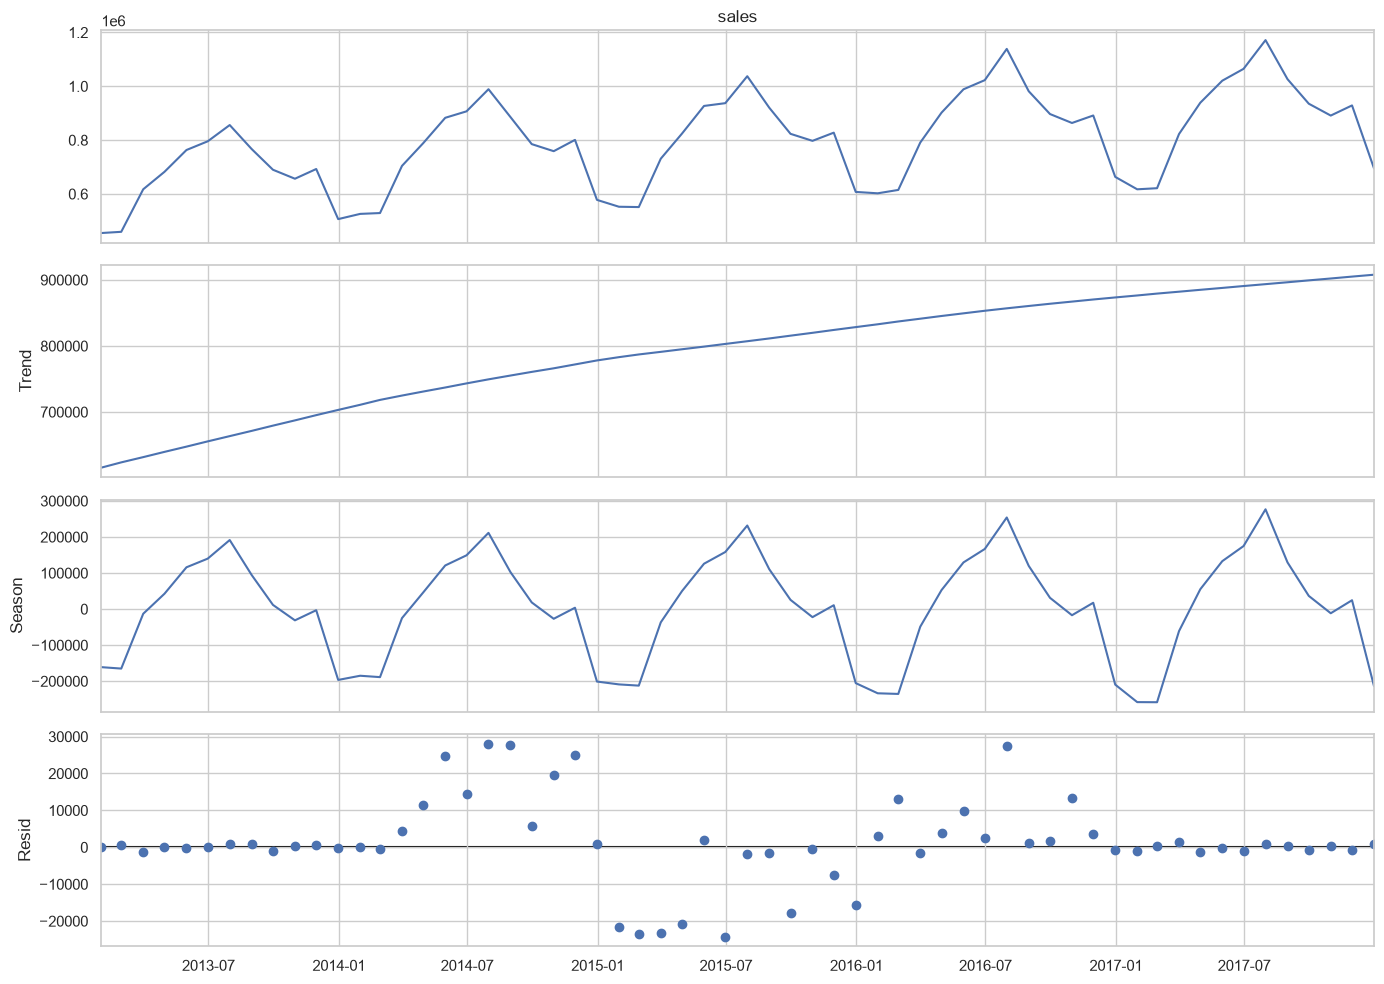

In [8]:
stl_result = STL(
    monthly_sales,
    period=12,
    robust=True
).fit()

stl_result.plot()

plt.gcf().set_size_inches(14, 10)
plt.tight_layout()
plt.show()

Cell 8 — STL decomposition for daily sales

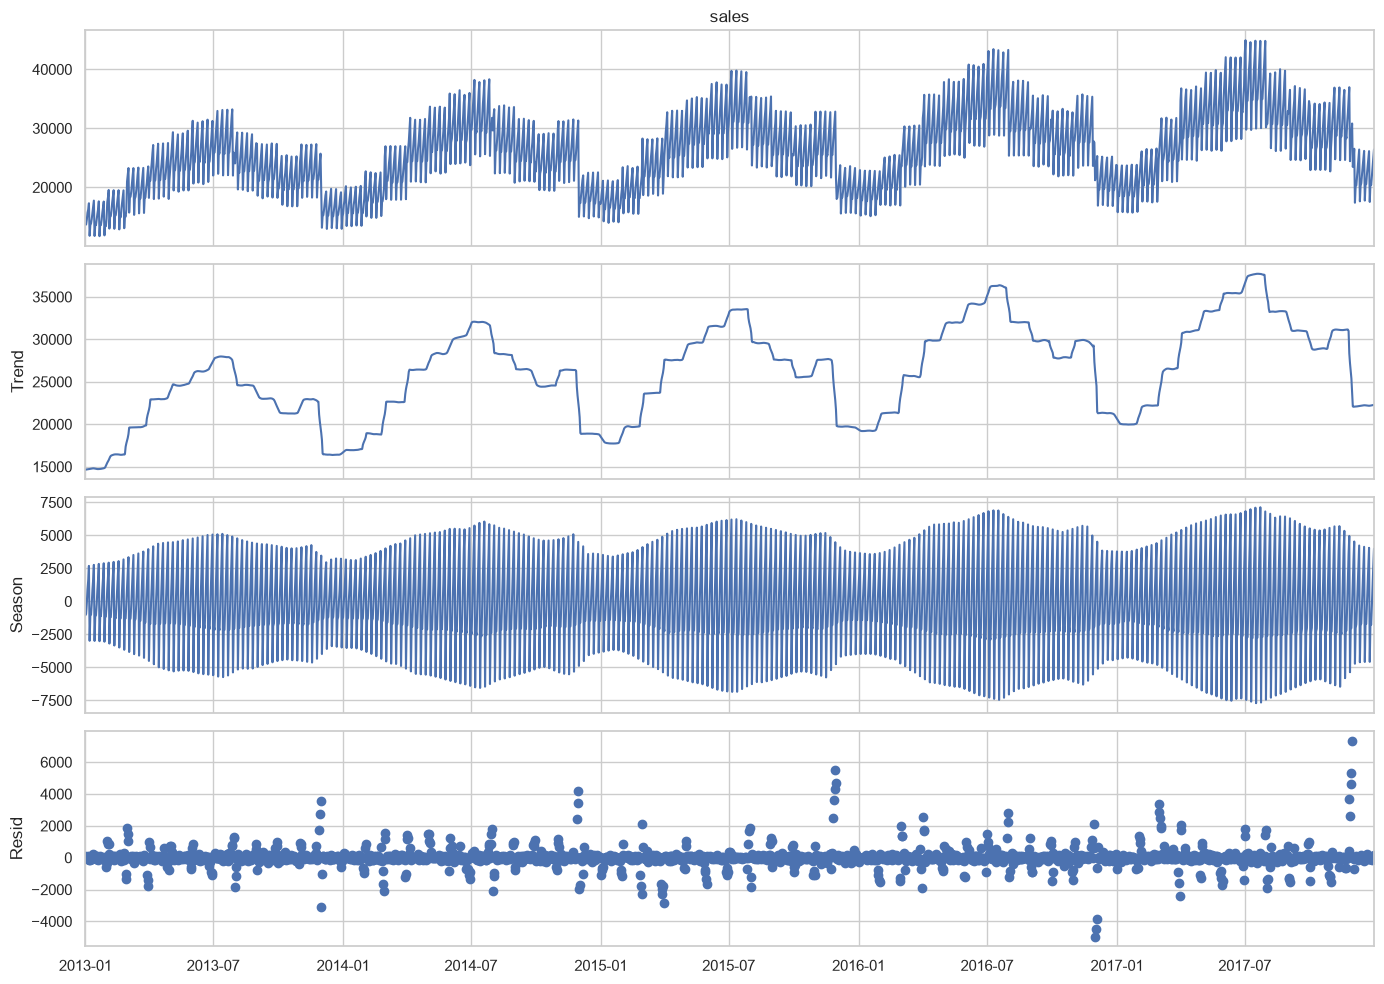

In [9]:
daily_stl_result = STL(
    daily_sales,
    period=7,
    robust=True
).fit()

daily_stl_result.plot()

plt.gcf().set_size_inches(14, 10)
plt.tight_layout()
plt.show()

Average weekly seasonal effect:


Monday      -5412.476095
Tuesday     -1964.497579
Wednesday   -1980.683191
Thursday     -238.970507
Friday       1474.536847
Saturday     3203.704867
Sunday       4916.174615
Name: season, dtype: float64

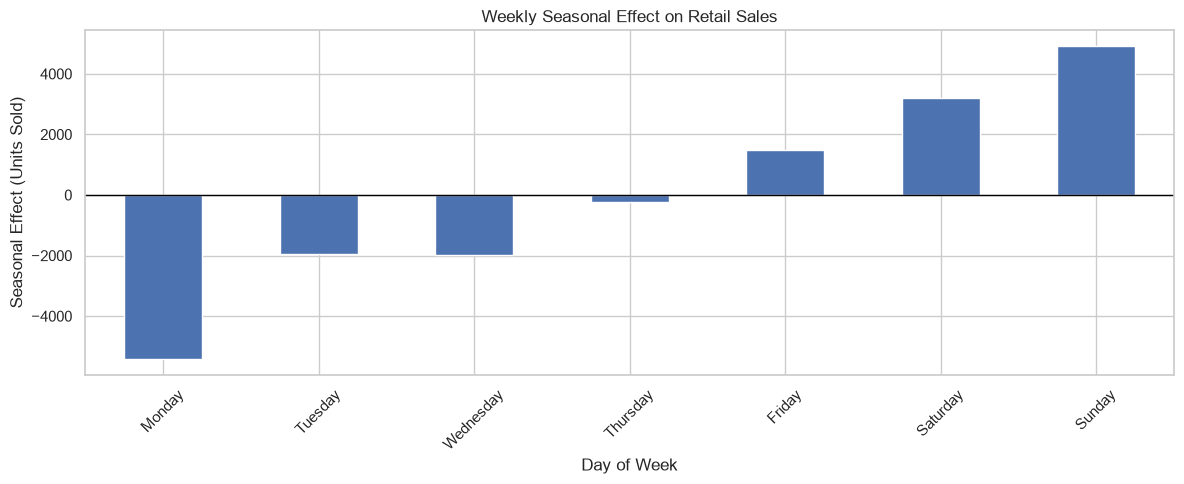

In [10]:
# Extract weekly seasonal component
weekly_seasonality = daily_stl_result.seasonal

# Calculate average seasonal effect for each weekday
weekday_seasonality = weekly_seasonality.groupby(
    weekly_seasonality.index.day_of_week
).mean()

# Give weekdays readable names
weekday_seasonality.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

print("Average weekly seasonal effect:")
display(weekday_seasonality)

# Visualize
weekday_seasonality.plot(kind="bar", figsize=(12, 5))

plt.title("Weekly Seasonal Effect on Retail Sales")
plt.xlabel("Day of Week")
plt.ylabel("Seasonal Effect (Units Sold)")
plt.xticks(rotation=45)
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

# Decomposition Analysis – Key Findings

## 1. Additive vs Multiplicative Decomposition
- Additive decomposition represents seasonality in absolute units.
- Multiplicative decomposition represents seasonality proportionally.
- Additive RMSE: 15,338.05
- Multiplicative RMSE: 8,855.21
- Multiplicative decomposition achieved a lower in-sample reconstruction RMSE.

## 2. Annual Seasonality
- Monthly sales show a repeating annual pattern.
- July generally has higher sales.
- January generally has lower sales.

## 3. Weekly Seasonality
- Daily sales show a repeating weekly pattern.
- Sunday has the highest average sales.
- Monday has the lowest average sales.

## 4. STL Decomposition
- STL uses LOESS to estimate trend and seasonal components.
- Robust STL reduces the influence of unusual observations.
- Monthly STL captures annual seasonality (period=12).
- Daily STL captures weekly seasonality (period=7).

## 5. Conclusion
Retail sales contain both long-term growth and recurring seasonal patterns.
These patterns should be considered when developing forecasting models.

Note: The lower multiplicative reconstruction RMSE does not guarantee better future forecasting accuracy. This must be evaluated on unseen data.